# Bab 12 — Recurrent Layers for Variable-Length Data
**Acuan:** Trask, *Grokking Deep Learning*, Bab 12 (hlm. 209–229).

Tujuan: memahami mengapa urutan diperlukan, membangun recurrent state, dan menghitung backpropagation through time (BPTT). Korpus pola karakter dibuat sendiri, bukan teks Shakespeare buku.

## State dan bobot yang dipakai ulang
RNN menghitung h_t=tanh(x_t W_x+h_(t−1) W_h+b), lalu logits=h_t W_y+c. Matriks transisi W_h digunakan di setiap timestep: jumlah parameter tidak bertambah dengan panjang urutan. Berbeda dari rata-rata embedding, hasil recurrent state bergantung pada urutan. State awal direset antarcontoh independen agar informasi tidak bocor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng=np.random.default_rng(12)
alphabet='abc'; tokens={c:i for i,c in enumerate(alphabet)}
sequence=np.array([tokens[c] for c in 'abcabcabcabc'])
inputs=np.eye(3)[sequence[:-1]]; targets=sequence[1:]
Wx=rng.normal(0,.2,(3,6)); Wh=rng.normal(0,.2,(6,6)); Wy=rng.normal(0,.2,(6,3))
b=np.zeros(6); c=np.zeros(3)
def softmax(z):
    ex=np.exp(z-z.max()); return ex/ex.sum()
def forward(xs):
    hs=[np.zeros(6)]; ps=[]
    for x in xs:
        hs.append(np.tanh(x@Wx+hs[-1]@Wh+b)); ps.append(softmax(hs[-1]@Wy+c))
    return hs,np.array(ps)
print('States/output:',len(forward(inputs)[0]),forward(inputs)[1].shape)

States/output: 12 (11, 3)


## BPTT: error dari masa depan
Gradien hidden pada t menerima dua kontribusi: loss output pada t dan state berikutnya melalui W_h. Kalikan jumlahnya dengan 1−h_t², lalu akumulasi gradien setiap matriks yang dipakai ulang. Gradien dibagi jumlah timestep karena loss dirata-ratakan. Gradient clipping membatasi norm pembaruan ketika gradien membesar; clipping tidak memperbaiki vanishing gradient.

Wh gradient analytic/numeric: 0.00877720932583238 0.008777209303811873
Loss awal/akhir: 1.1316096945315517 0.004072069901107545


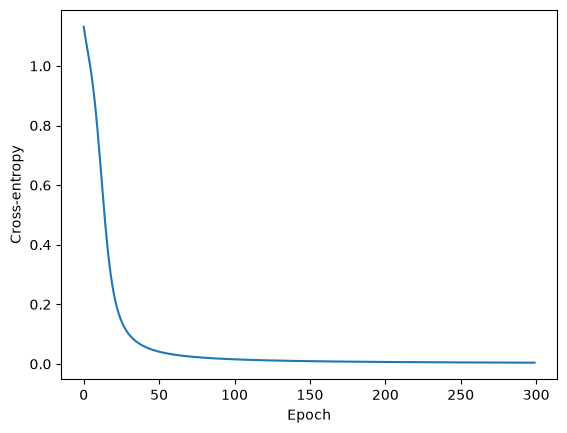

In [2]:
def gradients(xs,ys):
    hs,ps=forward(xs)
    gWx=np.zeros_like(Wx); gWh=np.zeros_like(Wh); gWy=np.zeros_like(Wy)
    gb=np.zeros_like(b); gc=np.zeros_like(c); future=np.zeros(6)
    for t in reversed(range(len(xs))):
        dz=ps[t].copy(); dz[ys[t]]-=1; dz/=len(xs)
        gWy+=np.outer(hs[t+1],dz); gc+=dz
        dh=(dz@Wy.T+future)*(1-hs[t+1]**2)
        gWx+=np.outer(xs[t],dh); gWh+=np.outer(hs[t],dh); gb+=dh
        future=dh@Wh.T
    loss=-np.log(ps[np.arange(len(ys)),ys]+1e-12).mean()
    return loss,[gWx,gWh,gWy,gb,gc]
loss,g=gradients(inputs,targets)
original=Wh[0,0]; eps=1e-5
Wh[0,0]=original+eps; plus=gradients(inputs,targets)[0]
Wh[0,0]=original-eps; minus=gradients(inputs,targets)[0]
Wh[0,0]=original
print('Wh gradient analytic/numeric:',g[1][0,0],(plus-minus)/(2*eps))
assert np.isclose(g[1][0,0],(plus-minus)/(2*eps),atol=1e-6)
losses=[]
for epoch in range(300):
    loss,gs=gradients(inputs,targets); losses.append(loss)
    norm=np.sqrt(sum(np.sum(a*a) for a in gs)); scale=min(1,1/(norm+1e-12))
    for parameter,grad in zip([Wx,Wh,Wy,b,c],gs): parameter-=.3*scale*grad
print('Loss awal/akhir:',losses[0],losses[-1])
plt.plot(losses); plt.xlabel('Epoch'); plt.ylabel('Cross-entropy'); plt.show()
assert losses[-1]<losses[0]

In [3]:
h=np.zeros(6); token=tokens['a']; generated='a'
for _ in range(20):
    h=np.tanh(np.eye(3)[token]@Wx+h@Wh+b)
    token=int(np.argmax(softmax(h@Wy+c))); generated+=alphabet[token]
print('Greedy generation:',generated)

Greedy generation: abcabcabcabcabcabcabc


## Ringkasan
State menyediakan representasi untuk urutan panjang bervariasi. BPTT menjumlahkan kontribusi bobot dari semua timestep, dan finite difference memeriksa implementasinya. Teks periodik pendek mudah dihafal; hasil generasi ini bukan bukti pemahaman bahasa. Urutan panjang meningkatkan biaya penyimpanan state dan risiko vanishing/exploding gradients, yang memotivasi LSTM dan truncated BPTT.